In [ ]:
import glob
import os

import pandas as pd

DATA_DIR = "/content"

# The lines we model, as (mode, line) pairs.
KEEP_LINES = [
    ("BUS", "1"),
    ("BUS", "4"),
    ("METRO", "10"),
    ("METRO", "19"),
    ("TRAM", "30"),
    ("TRAIN", "43"),
]

# Arrival delays outside this range are treated as data errors.
DELAY_MIN = -1800
DELAY_MAX = 1800

# A stop counts as late beyond three min.
LATE_THRESHOLD = 180

In [ ]:
import zipfile

with zipfile.ZipFile("/content/hogdalen_and_torkel_2024.zip") as z:
    z.extractall("/content")

print(os.listdir("/content"))

['.config', 'hogdalen_and_torkel_2024.zip', 'gtfs_rt_202401.csv.gz', 'modelling_data_2024.csv', 'hogdalen_2024.xlsx', 'weather_2024.csv', 'torkel_2024.xlsx', 'gtfs_rt_202401_hourly.csv', 'sample_data']


In [ ]:
#SLB weather stations

def load_slb(path, columns):
    """Read one SLB mast export.

    The files open with a metadata block of variable length, so we find the
    first row whose first cell parses as a date and start there.
    """
    raw = pd.read_excel(path, header=None)

    first_data_row = None
    for i in range(len(raw)):
        value = pd.to_datetime(raw.iloc[i, 0], errors="coerce")
        if pd.notna(value):
            first_data_row = i
            break

    if first_data_row is None:
        raise ValueError("No data rows found in " + path)

    table = raw.iloc[first_data_row:].copy()
    table = table.iloc[:, :len(columns)]
    table.columns = columns

    table["timestamp"] = pd.to_datetime(table["timestamp"], errors="coerce")
    table = table.dropna(subset=["timestamp"])

    for column in columns:
        if column != "timestamp":
            table[column] = pd.to_numeric(table[column], errors="coerce")

    # The files use hour-ending labels, shift back so the timestamp marks the start of the hour, like  the transport data is indexed.
    table["timestamp"] = table["timestamp"] - pd.Timedelta(hours=1)

    return table.reset_index(drop=True)


HOGDALEN_COLUMNS = [
    "timestamp", "maxvind", "globstral", "regn",
    "relfukt", "temp", "vindhast", "vindriktn",
]

TORKEL_COLUMNS = [
    "timestamp", "maxvind", "globstral", "regn", "relfukt",
    "temp", "lufttryck", "vindhast", "vindriktn",
]

hogdalen = load_slb(os.path.join(DATA_DIR, "hogdalen_2024.xlsx"), HOGDALEN_COLUMNS)
torkel = load_slb(os.path.join(DATA_DIR, "torkel_2024.xlsx"), TORKEL_COLUMNS)

# Hogdalen's humidity column is empty
hogdalen = hogdalen.drop(columns=["relfukt"])

print("hogdalen:", len(hogdalen), "rows,", hogdalen["timestamp"].min(), "to", hogdalen["timestamp"].max())
print("torkel:  ", len(torkel), "rows,", torkel["timestamp"].min(), "to", torkel["timestamp"].max())

# Keep the columns we actually use, and label them by station.
hog_small = hogdalen[["timestamp", "temp", "regn", "vindhast"]].copy()
hog_small.columns = ["timestamp", "temp_hog", "regn_hog", "wind_hog"]

tor_small = torkel[["timestamp", "temp", "regn", "vindhast"]].copy()
tor_small.columns = ["timestamp", "temp_tor", "regn_tor", "wind_tor"]

weather = hog_small.merge(tor_small, on="timestamp", how="outer")
weather = weather.sort_values("timestamp").reset_index(drop=True)

print("merged weather:", len(weather), "rows")
print(weather.isna().mean().round(3))


hogdalen: 8784 rows, 2024-01-01 00:00:00 to 2024-12-31 23:00:00
torkel:   8784 rows, 2024-01-01 00:00:00 to 2024-12-31 23:00:00
merged weather: 8784 rows
timestamp    0.000
temp_hog     0.000
regn_hog     0.000
wind_hog     0.000
temp_tor     0.014
regn_tor     0.014
wind_tor     0.013
dtype: float64


In [ ]:
# snow depth from SMHI, Vallentuna
import io
import requests

BASE = "https://opendata-download-metobs.smhi.se/api/version/1.0"
SNOW_STATION = 98310  # Vallentuna

url = (BASE + "/parameter/8/station/" + str(SNOW_STATION)
       + "/period/corrected-archive/data.csv")

response = requests.get(url)
response.encoding = "utf-8"
lines = response.text.split("\n")

header_index = None
for i, line in enumerate(lines):
    if line.startswith("Datum;Tid (UTC)"):
        header_index = i
        break

table = pd.read_csv(io.StringIO("\n".join(lines[header_index:])), sep=";", dtype=str)

snow = pd.DataFrame()
snow["timestamp"] = pd.to_datetime(
    table.iloc[:, 0] + " " + table.iloc[:, 1],
    format="%Y-%m-%d %H:%M:%S",
    utc=True,
    errors="coerce",
)
snow["snow_depth_cm"] = pd.to_numeric(table.iloc[:, 2], errors="coerce") * 100
snow = snow.dropna(subset=["timestamp"])

# SMHI is UTC everything else is local time.
snow["timestamp"] = snow["timestamp"].dt.tz_convert("Europe/Stockholm").dt.tz_localize(None)

snow = snow[snow["timestamp"] >= "2024-01-01"]
snow = snow[snow["timestamp"] <= "2024-12-31 23:59:59"]

print("snow readings:", len(snow))

weather = weather.drop_duplicates(subset=["timestamp"], keep="first")
snow = snow.drop_duplicates(subset=["timestamp"], keep="first")

weather = weather.merge(snow, on="timestamp", how="left")

weather["snow_depth_cm"] = weather["snow_depth_cm"].ffill(limit=30)
weather["snow_depth_cm"] = weather["snow_depth_cm"].fillna(0)

print("days with snow cover:", (weather["snow_depth_cm"] > 0).sum() / 24)


snow readings: 365
days with snow cover: 60.291666666666664


In [ ]:
#aggregate the monthly GTFS files

USE_COLUMNS = [
    "date",
    "LineNumber",
    "TransportMode",
    "scheduled_departure_time_sfm",
    "observed_arrival_delay",
]


def aggregate_month(path):
    """Reduce one monthly GTFS file to hourly means for the selected lines."""
    pieces = []

    reader = pd.read_csv(
        path,
        sep=";",
        usecols=USE_COLUMNS,
        dtype={"LineNumber": str},
        chunksize=500_000,
        compression="gzip",
    )

    for chunk in reader:
        # Filter on mode and line together.
        pairs = list(zip(chunk["TransportMode"], chunk["LineNumber"]))
        chunk = chunk[[p in KEEP_LINES for p in pairs]]

        chunk = chunk.dropna(subset=["observed_arrival_delay"])
        chunk = chunk[chunk["observed_arrival_delay"] >= DELAY_MIN]
        chunk = chunk[chunk["observed_arrival_delay"] <= DELAY_MAX]

        if len(chunk) == 0:
            continue

        # Seconds from midnight to hour of day. Values above 86400 belong to
        # trips running past midnight, so we wrap them.
        chunk["hour"] = (chunk["scheduled_departure_time_sfm"] // 3600) % 24
        chunk["is_late"] = chunk["observed_arrival_delay"] > LATE_THRESHOLD

        pieces.append(chunk)

    data = pd.concat(pieces, ignore_index=True)
    data["label"] = data["TransportMode"] + " " + data["LineNumber"]

    summary = data.groupby(["label", "date", "hour"]).agg(
        mean_delay=("observed_arrival_delay", "mean"),
        median_delay=("observed_arrival_delay", "median"),
        share_late=("is_late", "mean"),
        n_stops=("observed_arrival_delay", "size"),
    ).reset_index()

    return summary


monthly_files = sorted(glob.glob(os.path.join(DATA_DIR, "gtfs_rt_2024*.csv.gz")))
print("found", len(monthly_files), "monthly files")

all_months = []

for path in monthly_files:
    out_name = os.path.basename(path).replace(".csv.gz", "_hourly.csv")
    out_path = os.path.join(DATA_DIR, out_name)

    if os.path.exists(out_path):
        print("skipping", os.path.basename(path), "- already done")
        all_months.append(pd.read_csv(out_path))
        continue

    print("processing", os.path.basename(path), "...")
    summary = aggregate_month(path)
    print("  ", len(summary), "line-hours")
    summary.to_csv(out_path, index=False)
    all_months.append(summary)

delays = pd.concat(all_months, ignore_index=True)
print()
print("total line-hours:", len(delays))


found 12 monthly files
skipping gtfs_rt_202401.csv.gz - already done
skipping gtfs_rt_202402.csv.gz - already done
skipping gtfs_rt_202403.csv.gz - already done
skipping gtfs_rt_202404.csv.gz - already done
skipping gtfs_rt_202405.csv.gz - already done
skipping gtfs_rt_202406.csv.gz - already done
skipping gtfs_rt_202407.csv.gz - already done
skipping gtfs_rt_202408.csv.gz - already done
skipping gtfs_rt_202409.csv.gz - already done
skipping gtfs_rt_202410.csv.gz - already done
skipping gtfs_rt_202411.csv.gz - already done
processing gtfs_rt_202412.csv.gz ...
   4050 line-hours

total line-hours: 46599


In [ ]:
summary = aggregate_month(os.path.join(DATA_DIR, "gtfs_rt_202412.csv.gz"))
summary.to_csv(os.path.join(DATA_DIR, "gtfs_rt_202412_hourly.csv"), index=False)
print(len(summary))

4050


In [ ]:
print(monthly_files)
print([f for f in os.listdir(DATA_DIR) if "2024" in f])

['/content/gtfs_rt_202401.csv.gz', '/content/gtfs_rt_202402.csv.gz', '/content/gtfs_rt_202403.csv.gz', '/content/gtfs_rt_202404.csv.gz', '/content/gtfs_rt_202405.csv.gz', '/content/gtfs_rt_202406.csv.gz', '/content/gtfs_rt_202407.csv.gz', '/content/gtfs_rt_202408.csv.gz', '/content/gtfs_rt_202409.csv.gz', '/content/gtfs_rt_202410.csv.gz', '/content/gtfs_rt_202411.csv.gz', '/content/gtfs_rt_202412.csv.gz']
['gtfs_rt_202407.csv.gz', 'gtfs_rt_202411.csv.gz', 'gtfs_rt_202403.csv.gz', 'gtfs_rt_202406.csv.gz', 'gtfs_rt_202412_hourly.csv', 'gtfs_rt_202409_hourly.csv', 'gtfs_rt_202410.csv.gz', 'gtfs_rt_202408_hourly.csv', 'hogdalen_and_torkel_2024.zip', 'gtfs_rt_202407_hourly.csv', 'gtfs_rt_202403_hourly.csv', 'gtfs_rt_202405.csv.gz', 'gtfs_rt_202404.csv.gz', 'gtfs_rt_202404_hourly.csv', 'gtfs_rt_202410_hourly.csv', 'gtfs_rt_202409.csv.gz', 'gtfs_rt_202412.csv.gz', 'gtfs_rt_202401.csv.gz', 'modelling_data_2024.csv', 'gtfs_rt_202405_hourly.csv', 'hogdalen_2024.xlsx', 'weather_2024.csv', 'gtfs_r

In [ ]:
dec = pd.read_csv(os.path.join(DATA_DIR, "gtfs_rt_202412_hourly.csv"))
print(len(dec))
print(dec["label"].value_counts())
print(dec["date"].min(), dec["date"].max())

4050
label
METRO 19    701
TRAM 30     699
TRAIN 43    691
METRO 10    684
BUS 4       651
BUS 1       624
Name: count, dtype: int64
20241201 20241231


In [ ]:
#join and build features

delays["timestamp"] = (
    pd.to_datetime(delays["date"].astype(str), format="%Y%m%d")
    + pd.to_timedelta(delays["hour"], unit="h")
)

data = delays.merge(weather, on="timestamp", how="left")

data = data.drop_duplicates(subset=["label", "timestamp"], keep="first")
data = data.drop(columns=["snow_depth_cm_x", "snow_depth_cm_y"], errors="ignore")

print("rows:", len(data))
print("rows with no weather:", data["temp_tor"].isna().sum())


# Average the two stations where both reported, so a gap at one station
# does not lose the hour entirely
data["temperature"] = data[["temp_hog", "temp_tor"]].mean(axis=1)
data["precipitation"] = data[["regn_hog", "regn_tor"]].mean(axis=1)
data["wind"] = data[["wind_hog", "wind_tor"]].mean(axis=1)

# Accumulation matters more than the single hour
weather_sorted = weather.sort_values("timestamp").copy()
weather_sorted["precip_mean"] = weather_sorted[["regn_hog", "regn_tor"]].mean(axis=1)
weather_sorted["precip_3h"] = weather_sorted["precip_mean"].rolling(3, min_periods=1).sum()
weather_sorted["precip_24h"] = weather_sorted["precip_mean"].rolling(24, min_periods=1).sum()

data = data.merge(
    weather_sorted[["timestamp", "precip_3h", "precip_24h"]],
    on="timestamp",
    how="left",
)

# Frozen prexip
data["frozen_precip"] = data["precip_3h"] * (data["temperature"] < 1)
data["is_freezing"] = (data["temperature"] < 0).astype(int)

data["weekday"] = data["timestamp"].dt.dayofweek
data["is_weekend"] = (data["weekday"] >= 5).astype(int)
data["month"] = data["timestamp"].dt.month

data = data.sort_values(["label", "timestamp"]).reset_index(drop=True)

data.to_csv(os.path.join(DATA_DIR, "modelling_data_2024.csv"), index=False)

print()
print("Wrote modelling_data_2024.csv")
print("rows:", len(data))
print()
print(data.groupby("label")["mean_delay"].agg(["mean", "size"]).round(1))
print()
print(data[["temperature", "precipitation", "precip_3h", "snow_depth_cm"]].describe().round(2))


rows: 46599
rows with no weather: 640

Wrote modelling_data_2024.csv
rows: 46599

           mean  size
label                
BUS 1     143.8  7376
BUS 4      99.6  7641
METRO 10  -53.4  7959
METRO 19  -30.0  8217
TRAIN 43   35.7  7182
TRAM 30   -17.9  8224

       temperature  precipitation  precip_3h  snow_depth_cm
count     46599.00       46599.00   46599.00       46599.00
mean          8.52           0.06       0.18           1.70
std           8.34           0.34       0.83           4.82
min         -14.53           0.00       0.00           0.00
25%           1.93           0.00       0.00           0.00
50%           7.94           0.00       0.00           0.00
75%          15.61           0.00       0.00           0.00
max          27.78          10.87      17.75          24.00


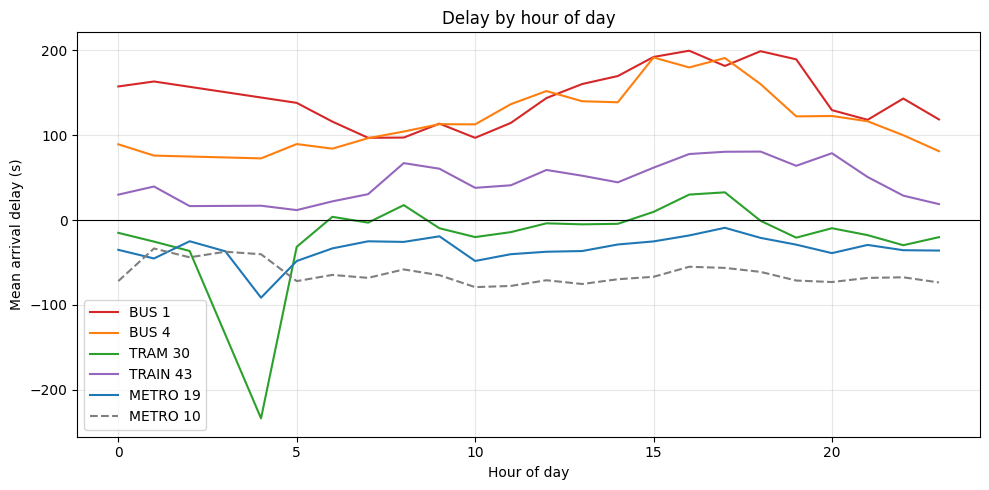

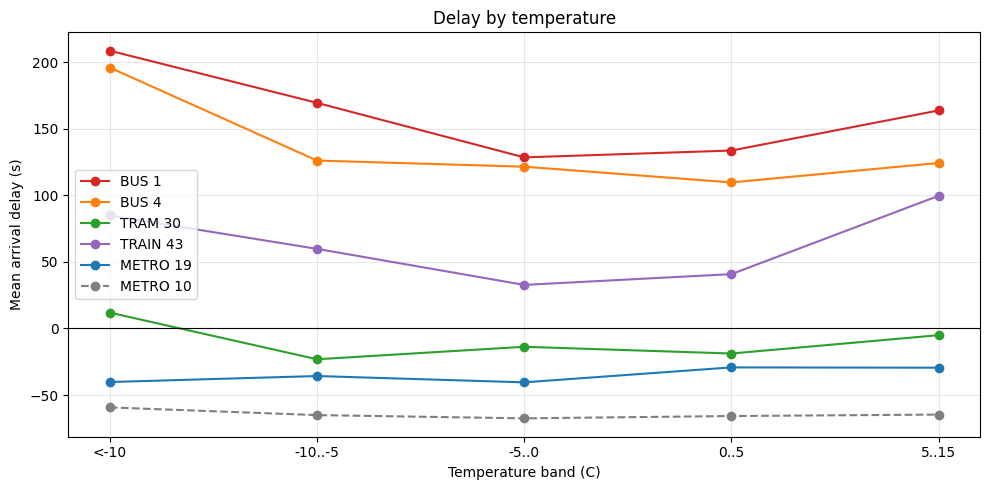

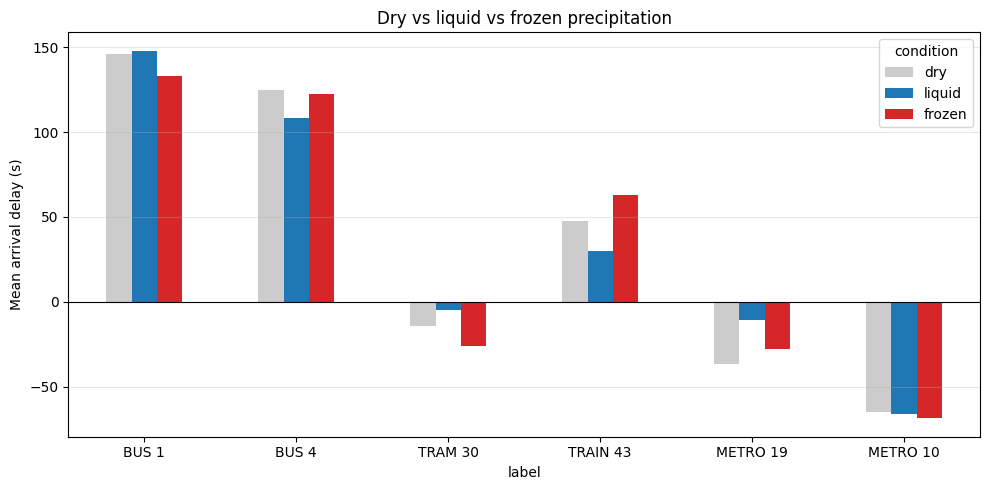

hours in each condition:
condition
dry       1050
frozen     116
liquid      79
dtype: int64


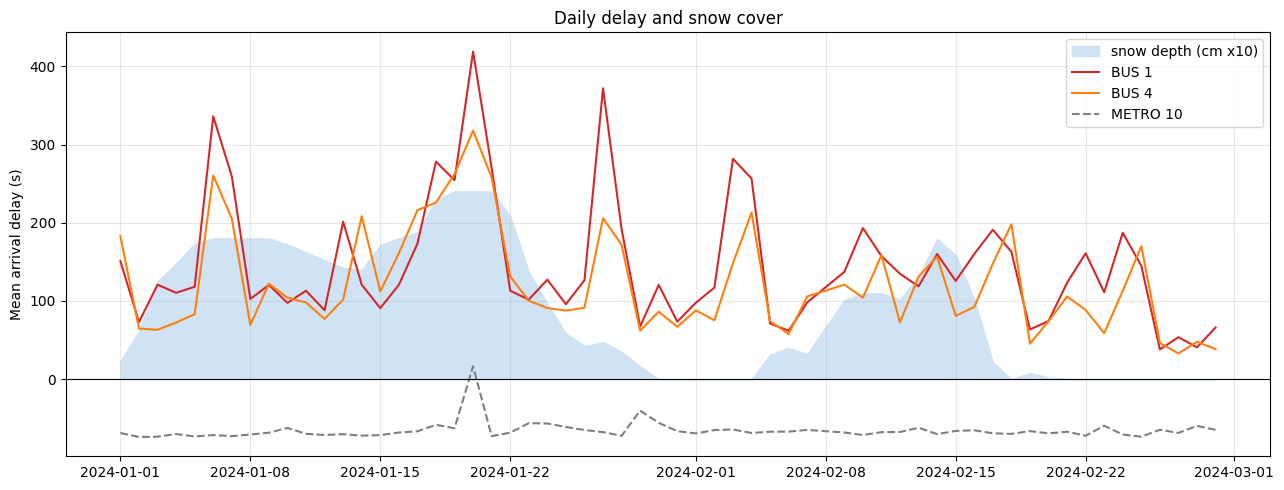

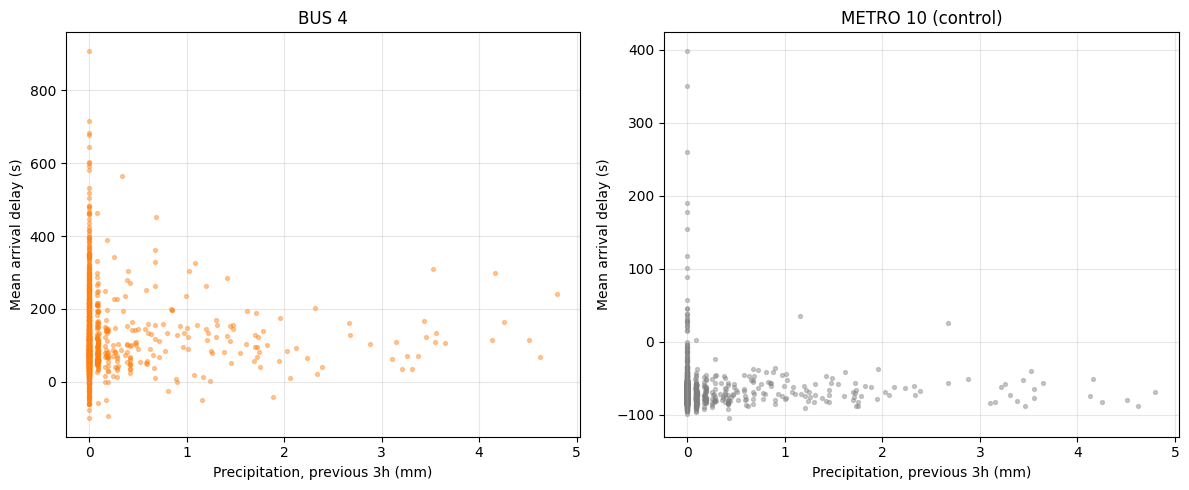

In [ ]:
"""
Plots for modelling_data_2024.csv.

Paste as one cell. Works on a single month or the full year.
"""

import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv(os.path.join(DATA_DIR, "modelling_data_2024.csv"))
data["timestamp"] = pd.to_datetime(data["timestamp"])


LINE_ORDER = ["BUS 1", "BUS 4", "TRAM 30", "TRAIN 43", "METRO 19", "METRO 10"]
COLOURS = {
    "BUS 1": "#d62728",
    "BUS 4": "#ff7f0e",
    "TRAM 30": "#2ca02c",
    "TRAIN 43": "#9467bd",
    "METRO 19": "#1f77b4",
    "METRO 10": "#7f7f7f",
}


#delay by hour of day

fig, ax = plt.subplots(figsize=(10, 5))

for label in LINE_ORDER:
    subset = data[data["label"] == label]
    series = subset.groupby("hour")["mean_delay"].mean()
    style = "--" if label == "METRO 10" else "-"
    ax.plot(series.index, series.values, style, label=label, color=COLOURS[label])

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean arrival delay (s)")
ax.set_title("Delay by hour of day")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# delay against temperature, binned

temp_bins = [-25, -10, -5, 0, 5, 15, 40]
temp_labels = ["<-10", "-10..-5", "-5..0", "0..5", "5..15", ">15"]
data["temp_band"] = pd.cut(data["temperature"], temp_bins, labels=temp_labels)

fig, ax = plt.subplots(figsize=(10, 5))

table = data.pivot_table(
    index="temp_band", columns="label", values="mean_delay", observed=False
)

for label in LINE_ORDER:
    if label in table.columns:
        style = "--" if label == "METRO 10" else "-"
        ax.plot(range(len(table)), table[label], style, marker="o",
                label=label, color=COLOURS[label])

ax.set_xticks(range(len(table)))
ax.set_xticklabels(table.index)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Temperature band (C)")
ax.set_ylabel("Mean arrival delay (s)")
ax.set_title("Delay by temperature")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#frozen vs liquid precipitation

def condition(row):
    if row["precip_3h"] <= 0.1:
        return "dry"
    if row["temperature"] < 1:
        return "frozen"
    return "liquid"


data["condition"] = data.apply(condition, axis=1)

table = data.pivot_table(
    index="label", columns="condition", values="mean_delay"
)
table = table.reindex(LINE_ORDER)
table = table[["dry", "liquid", "frozen"]]

table.plot(kind="bar", figsize=(10, 5),
           color=["#cccccc", "#1f77b4", "#d62728"])
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Mean arrival delay (s)")
plt.title("Dry vs liquid vs frozen precipitation")
plt.xticks(rotation=0)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("hours in each condition:")
print(data[data["label"] == "BUS 4"].groupby("condition").size())


# daily delay with snow depth behind it

daily = data.groupby([data["timestamp"].dt.date, "label"]).agg(
    delay=("mean_delay", "mean"),
    snow=("snow_depth_cm", "mean"),
).reset_index()
daily.columns = ["date", "label", "delay", "snow"]
daily["date"] = pd.to_datetime(daily["date"])

fig, ax = plt.subplots(figsize=(13, 5))

snow_by_day = daily.groupby("date")["snow"].mean()
ax.fill_between(snow_by_day.index, 0, snow_by_day.values * 10,
                color="#cfe3f5", label="snow depth (cm x10)", zorder=0)

for label in ["BUS 1", "BUS 4", "METRO 10"]:
    subset = daily[daily["label"] == label]
    style = "--" if label == "METRO 10" else "-"
    ax.plot(subset["date"], subset["delay"], style,
            label=label, color=COLOURS[label], zorder=2)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean arrival delay (s)")
ax.set_title("Daily delay and snow cover")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# scatter, bus 4 against metro 10

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

for ax, label in zip(axes, ["BUS 4", "METRO 10"]):
    subset = data[data["label"] == label]
    ax.scatter(subset["precip_3h"], subset["mean_delay"],
               s=8, alpha=0.4, color=COLOURS[label])
    ax.set_xlabel("Precipitation, previous 3h (mm)")
    ax.set_ylabel("Mean arrival delay (s)")
    ax.set_title(label + (" (control)" if label == "METRO 10" else ""))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()